# Results and graphs

Recorded results compare FP32 and INT8 accuracy, matrix-stage latency, and the
effects of lane count and bandwidth. Timing covers matrix calculations and
transfers, excluding bias, activation, rescaling, and choosing a digit. Rates
are computed from one image's matrix stages, not complete predictions/second.
Notebook 05 verifies real values on 16 images; the larger timing sweeps in
notebook 03 use matching matrix dimensions. Graph inputs are still recorded
numbers rather than automatically loaded experiment exports.


## 1. FP32 vs INT8 Accuracy

These recorded values come from notebook 05 using seed 530, eight epochs,
1,000 separate calibration images, and 10,000 test images. The INT8 result uses
INT32 biases and integer rescaling with an INT64 temporary. Its intermediate
scale is frozen before testing. The numbers below are a saved result snapshot,
not a rerun of the network. The mixed-precision reference produced the same
predictions in this run.


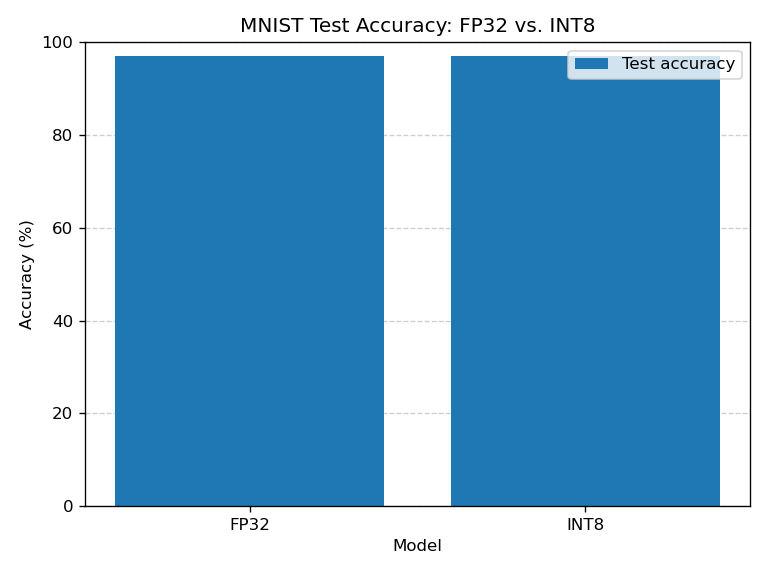

In [1]:
import matplotlib.pyplot as plt

models = ["FP32", "INT8"]
accuracy = [96.96, 96.98]

fig, ax = plt.subplots()
ax.bar(models, accuracy, label="Test accuracy")
ax.set_title("MNIST Test Accuracy: FP32 vs. INT8")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()


### Observation

The FP32 model achieved 96.96% accuracy and the
integer INT8 path achieved 96.98%, a difference
of 0.02 percentage points.
Their predictions differed on 15 of 10,000 images.
This run retained similar accuracy after quantization; the small increase does
not establish that INT8 is inherently more accurate.


## 2. FP32 vs INT8 matrix-stage latency

These modeled times sum the two matrix stages for one image at eight lanes,
32 bytes/cycle for each bus, and an assumed 100 MHz clock. Real-value checks
in notebook 05 reproduce the baseline cycle totals. The other prediction
operations are excluded, so these are not complete inference times.


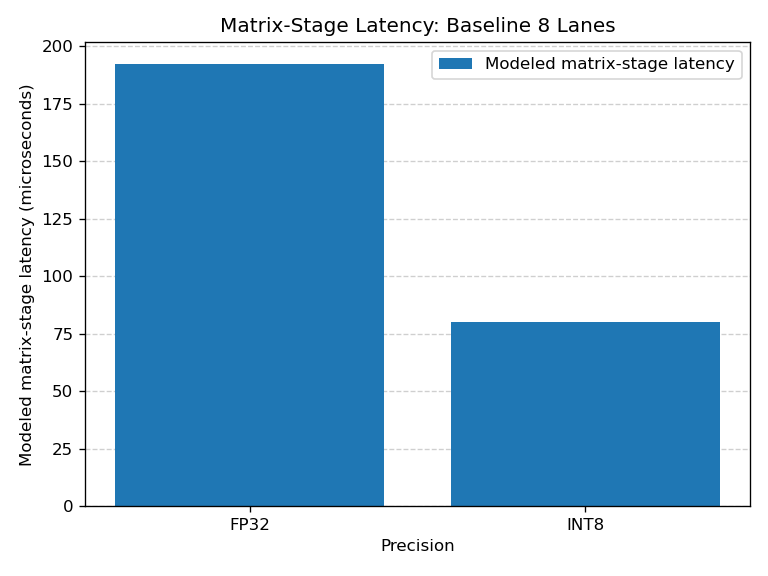

In [2]:
import matplotlib.pyplot as plt

precisions = ["FP32", "INT8"]
latency_us = [192.04, 80.25]

fig, ax = plt.subplots()
ax.bar(precisions, latency_us, label="Modeled matrix-stage latency")
ax.set_title("Matrix-Stage Latency: Baseline 8 Lanes")
ax.set_xlabel("Precision")
ax.set_ylabel("Modeled matrix-stage latency (microseconds)")
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()


### Observation

The baseline matrix-stage time is 192.04 microseconds for FP32 versus 80.25 for
INT8, about 2.39× modeled speedup. Smaller operands reduce transfer costs and
allow more MACs under the same local read budget. This comparison excludes the
other operations needed to produce a prediction.


## 3. Matrix-stage rate vs accelerator lanes

Compare 4, 8, 16, and 32 lanes with other hardware settings fixed. Rates are the
assumed clock divided by one image's summed matrix-stage cycles.


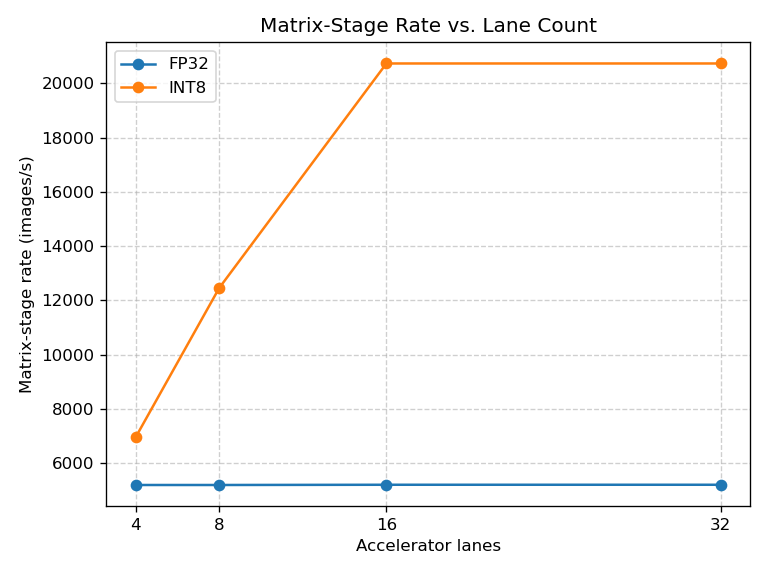

In [3]:
import matplotlib.pyplot as plt

lanes = [4, 8, 16, 32]
fp32_throughput = [5207.25, 5207.25, 5215.94, 5215.94]
int8_throughput = [6963.30, 12461.06, 20725.39, 20725.39]

fig, ax = plt.subplots()
ax.plot(lanes, fp32_throughput, marker="o", label="FP32")
ax.plot(lanes, int8_throughput, marker="o", label="INT8")
ax.set_title("Matrix-Stage Rate vs. Lane Count")
ax.set_xlabel("Accelerator lanes")
ax.set_ylabel("Matrix-stage rate (images/s)")
ax.set_xticks(lanes)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()


### Observation

FP32 matrix-stage rate stays near 5,200 images/s. INT8 rises from approximately
6,963 at four lanes to 20,725 at 16 lanes, then stays unchanged at 32 lanes.
The 32-byte/cycle local bus supplies at most 16 INT8 or four FP32 MACs/cycle;
adding more lanes alone cannot exceed that operand-read limit.


## 4. INT8 matrix-stage rate vs external bandwidth

At 32 lanes, vary external bandwidth while the local read budget stays at
32 bytes/cycle. This changes transfer time without changing the compute read
limit. Rates still exclude bias, activation, rescaling, and digit selection.


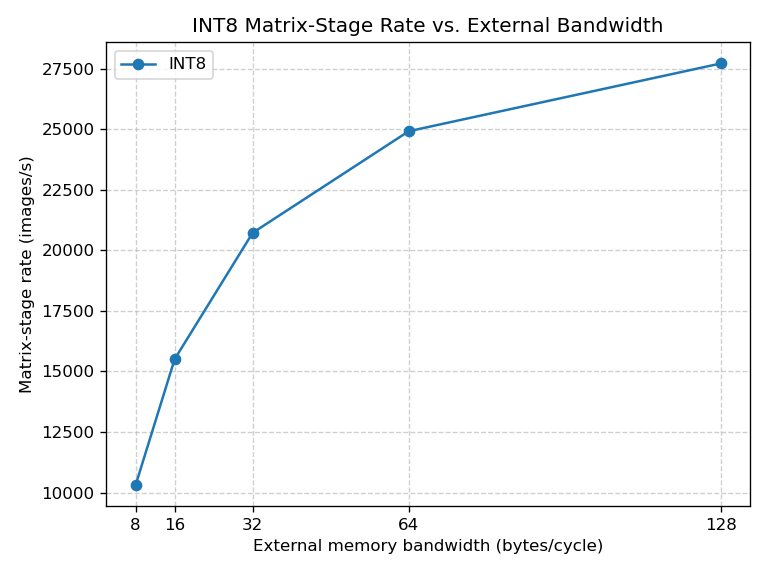

In [4]:
import matplotlib.pyplot as plt

bandwidth = [8, 16, 32, 64, 128]
int8_throughput = [10314.60, 15508.68, 20725.39, 24919.01, 27716.19]

fig, ax = plt.subplots()
ax.plot(bandwidth, int8_throughput, marker="o", label="INT8")
ax.set_title("INT8 Matrix-Stage Rate vs. External Bandwidth")
ax.set_xlabel("External memory bandwidth (bytes/cycle)")
ax.set_ylabel("Matrix-stage rate (images/s)")
ax.set_xticks(bandwidth)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()


### Observation

The INT8 matrix-stage rate rises from about 10,315 images/s at eight external
bytes/cycle to 27,716 at 128 bytes/cycle. Faster external transfers shorten the
load/store phases. They do not remove the separate 16-MAC/cycle local read cap,
which explains why the earlier lane sweep plateaued. Both resources matter.
